# BAI KIEM TRA KI NANG SO 2: HUAN LUYEN VA DANH GIA MO HINH HOC MAY
## De tai: Phan tich quan diem phan hoi cua nguoi dung ve ung dung di dong (Ma de tai: NLP-01)
**Hoc phan:** Hoc may (Machine Learning)  
**Giang vien giang day:** ThS. Ha Thi Thanh  
**Khoa / Bo mon:** Khoa CNTT - Bo mon KHMT  
**Lop hoc phan:** CNTT K22B + K22C  
**Nhom thuc hien:** NHOM 12  

### Bang phan cong nhiem vu thanh vien:

| STT | Ma sinh vien | Ho va ten | Nhiem vu chinh phu trach |
| :-: | :---: | :--- | :--- |
| 1 | DTC235200483 | **Luu Thi Khanh Ly** | Thu thap du lieu, Kham pha & Truc quan hoa du lieu (EDA) |
| 2 | DTC235200647 | **Le Hong Son (#)** | Truong nhom - Tien xu ly du lieu, Xay dung va huan luyen mo hinh |
| 3 | DTC235200645 | **Ngo Thi Sinh** | Danh gia mo hinh, Phan tich ma tran nham lan (Error Analysis) |
| 4 | DTC235200811 | **Nguyen Thanh Tung** | Trien khai kien truc pipeline, Xay dung ung dung Demo Streamlit |

---
### Muc tieu thuc hien trong Bai kiem tra ki nang so 2:
1. **Chuan bi du lieu huan luyen:** Nap tap du lieu da tien xu ly `data/app_reviews_cleaned.csv`, thiet lap bai toan phan loai nhi phan (0: Tieu cuc, 1: Tich cuc).
2. **Phan chia du lieu phan tang (Stratified Splitting):** Chia theo ty le 70% Train, 15% Validation, 15% Test bao toan ty le phan bo nhan.
3. **Trich xuat dac trung van ban TF-IDF:** Cau hinh Unigrams + Bigrams, chuan hoa L2 Norm va phong chong ro ri du lieu (Data Leakage).
4. **Huan luyen 3 thuat toan hoc may:**
   - *Baseline:* Multinomial Naive Bayes (MNB)
   - *Mo hinh tuyen tinh:* Logistic Regression (can bang trong so `class_weight='balanced'`)
   - *Mo hinh le cuc dai:* Linear Support Vector Machine (LinearSVC)
5. **Danh gia va So sanh toan dien:** So sanh cac chi so Accuracy, Precision, Recall, Macro F1-Score tren ca tap Validation va tap Test.
6. **Truc quan hoa chuyen sau:** Ve Ma tran nham lan (Confusion Matrix), trich xuat Top 15 dac trung tu vung quan trong va mo xe mau du doan sai (Error Analysis).
7. **Dong goi mo hinh:** Xuat mo hinh toi uu ra tep `models/best_sentiment_model.joblib` va `models/tfidf_vectorizer.joblib`.

---
## BUOC 1: KHAI BAO THU VIEN VA NAP DU LIEU DA TIEN XU LY
Khai bao cac thu vien Khoa hoc du lieu chuan (`pandas`, `numpy`, `matplotlib`, `seaborn`) va he sinh thai thuat toan Hoc may `scikit-learn`.

In [1]:
import os
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Cau hinh giao dien bieu do chuan hoc thuat
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Times New Roman']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid", palette="muted")

# Doc tep du lieu da tien xu ly sach
data_path = 'data/app_reviews_cleaned.csv'
if not os.path.exists(data_path):
    data_path = '../data/app_reviews_cleaned.csv'

df = pd.read_csv(data_path)
print(f"=== NAP THANH CONG DU LIEU: {data_path} ===")
print(f"Kich thuoc tap du lieu sach: {df.shape[0]} dong, {df.shape[1]} cot\n")
display(df[['review_id', 'app_name', 'rating', 'sentiment', 'cleaned_content']].head())

=== NAP THANH CONG DU LIEU: data/app_reviews_cleaned.csv ===
Kich thuoc tap du lieu sach: 14869 dong, 10 cot



,review_id,app_name,rating,sentiment,cleaned_content
0,5800709584,Agribank,5,Tich cuc,ng i d ng agribank ng d ng th t ti n ch v tuy ...
1,3875076399,Agribank,5,Tich cuc,ng i d ng agribank m c th ng b o bi n ng s d t...
2,5822273640,Agribank,5,Tich cuc,b n n ng c p ang gi ng n h ng agribank bi t l ...
3,5793415302,Agribank,5,Tich cuc,ung dung e banking sau khi update phi n b n m ...
4,9093171210,Agribank,1,Tieu cuc,ung dung ho t ng ch a t t ng n h ng c n c i th...


---
## BUOC 2: PHAN CHIA TAP DU LIEU PHAN TANG (STRATIFIED SPLIT 70 / 15 / 15)
Chung ta thiet lap bai toan phan loai nhi phan:
* **Nhan 0 (Tieu cuc):** Danh gia 1 sao va 2 sao.
* **Nhan 1 (Tich cuc):** Danh gia 4 sao va 5 sao.

Su dung phuong phap phan tang (`stratify=y`) de giu nguyen ty le can bang giua cac lop tren ca 3 tap:
* **Tap Train (70%):** Duyen luyen mo hinh va hoc bo tu dien TF-IDF.
* **Tap Validation (15%):** Danh gia kiem dinh cheo, lua chon sieu tham so.
* **Tap Test (15%):** Danh gia khach quan doc lap tren du lieu chua tung thay (Unseen data).

In [2]:
# 1. Chuan hoa nhan nhi phan
sentiment_map = {
    'Tieu cuc': 0, 'Tiêu cực': 0,
    'Tich cuc': 1, 'Tích cực': 1
}
df_binary = df[df['sentiment'].isin(sentiment_map.keys())].copy()
df_binary['label'] = df_binary['sentiment'].map(sentiment_map)

X = df_binary['cleaned_content'].astype(str)
y = df_binary['label'].astype(int)

print(f"Tong so mau dua vao huan luyen: {len(df_binary)}")
print(f"- Nhan 0 (Tieu cuc): {sum(y == 0)} mau ({sum(y == 0) / len(y) * 100:.2f}%)")
print(f"- Nhan 1 (Tich cuc): {sum(y == 1)} mau ({sum(y == 1) / len(y) * 100:.2f}%)")

# 2. Phan chia 70% Train, 15% Validation, 15% Test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1765, stratify=y_train_val, random_state=42
)

print("\n=== KET QUA PHAN CHIA TAP DU LIEU ===")
print(f"1. Tap Train (70%):      {len(X_train)} mau")
print(f"2. Tap Validation (15%): {len(X_val)} mau")
print(f"3. Tap Test (15%):       {len(X_test)} mau")

Tong so mau dua vao huan luyen: 14299
- Nhan 0 (Tieu cuc): 9826 mau (68.72%)
- Nhan 1 (Tich cuc): 4473 mau (31.28%)

=== KET QUA PHAN CHIA TAP DU LIEU ===
1. Tap Train (70%):      10008 mau
2. Tap Validation (15%): 2146 mau
3. Tap Test (15%):       2145 mau


---
## BUOC 3: TRICH XUAT DAC TRUNG VAN BAN BANG TF-IDF (N-GRAM 1-2, L2 NORM)
Ap dung ky thuat vector hoa **TF-IDF (Term Frequency - Inverse Document Frequency)**:
* **N-gram (1, 2):** Ket hop tu don (Unigrams) va cum 2 tu (Bigrams) de giu nguyen ngu canh phu dinh nhu `khong_tot`, `chuyen_tien`.
* **Chuan hoa L2 Norm (`norm='l2'`):** Thu nho moi vector dac trung ve do dai bang 1, giup triet tieu su chenh lech do do dai cau gay ra.
* **Nguyen tac chong ro ri du lieu (Data Leakage):** Chi goi `fit_transform()` tren tap Train; tap Val va Test tuyet doi chi goi `transform()`.

In [3]:
# Thiet lap bo vector hoa TF-IDF
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.9,
    sublinear_tf=True,
    norm='l2'
)

# Fit tren tap Train, transform sang Val va Test
X_train_vec = vectorizer.fit_transform(X_train)
X_val_vec = vectorizer.transform(X_val)
X_test_vec = vectorizer.transform(X_test)

print(f"So luong dac trung tu vung (Vocabulary size): {len(vectorizer.vocabulary_)} dac trung")
print(f"Kich thuoc ma tran Train: {X_train_vec.shape}")
print(f"Kich thuoc ma tran Val:   {X_val_vec.shape}")
print(f"Kich thuoc ma tran Test:  {X_test_vec.shape}")

So luong dac trung tu vung (Vocabulary size): 8163 dac trung
Kich thuoc ma tran Train: (10008, 8163)
Kich thuoc ma tran Val:   (2146, 8163)
Kich thuoc ma tran Test:  (2145, 8163)


---
## BUOC 4: HUAN LUYEN VA DANH GIA CAC MO HINH HOC MAY
Nhom trien khai huan luyen va so sanh doi chung 3 thuat toan hoc may phan loai:
1. **Multinomial Naive Bayes (MNB):** Mo hinh co so (Baseline) dua tren xac suat thong ke, tinh toan nhanh.
2. **Logistic Regression (LR):** Mo hinh hoi quy logistic voi tham so can bang trong so `class_weight='balanced'` de khac phuc mat can bang du lieu.
3. **Linear Support Vector Machine (LinearSVC):** Mo hinh toi uu hoa le phan tach cuc dai, hoat dong dac biet hieu qua tren khong gian vector thua nhieu chieu.

In [4]:
models = {
    'Multinomial Naive Bayes': MultinomialNB(alpha=1.0),
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42, C=1.0),
    'Linear SVC': LinearSVC(class_weight='balanced', random_state=42, C=1.0, max_iter=2000)
}

results = []
trained_models = {}

print("=" * 85)
print(f"{'Mo hinh':<26} | {'Tap':<5} | {'Accuracy':<8} | {'Precision':<9} | {'Recall':<8} | {'Macro F1':<8}")
print("=" * 85)

for name, model in models.items():
    model.fit(X_train_vec, y_train)
    trained_models[name] = model

    # Danh gia tren tap Validation
    y_val_pred = model.predict(X_val_vec)
    val_acc = accuracy_score(y_val, y_val_pred)
    val_p = precision_score(y_val, y_val_pred, average='macro', zero_division=0)
    val_r = recall_score(y_val, y_val_pred, average='macro', zero_division=0)
    val_f1 = f1_score(y_val, y_val_pred, average='macro', zero_division=0)

    # Danh gia tren tap Test
    y_test_pred = model.predict(X_test_vec)
    test_acc = accuracy_score(y_test, y_test_pred)
    test_p = precision_score(y_test, y_test_pred, average='macro', zero_division=0)
    test_r = recall_score(y_test, y_test_pred, average='macro', zero_division=0)
    test_f1 = f1_score(y_test, y_test_pred, average='macro', zero_division=0)

    results.append({
        'Mo hinh': name,
        'Val_Accuracy': val_acc, 'Val_Precision': val_p, 'Val_Recall': val_r, 'Val_Macro_F1': val_f1,
        'Test_Accuracy': test_acc, 'Test_Precision': test_p, 'Test_Recall': test_r, 'Test_Macro_F1': test_f1,
        'y_test_pred': y_test_pred
    })

    print(f"{name:<26} | {'Val':<5} | {val_acc:<8.4f} | {val_p:<9.4f} | {val_r:<8.4f} | {val_f1:<8.4f}")
    print(f"{name:<26} | {'Test':<5} | {test_acc:<8.4f} | {test_p:<9.4f} | {test_r:<8.4f} | {test_f1:<8.4f}")
    print("-" * 85)

df_results = pd.DataFrame(results)

Mo hinh                    | Tap   | Accuracy | Precision | Recall   | Macro F1
Multinomial Naive Bayes    | Val   | 0.8108   | 0.8624    | 0.7056   | 0.7308  
Multinomial Naive Bayes    | Test  | 0.8168   | 0.8584    | 0.7181   | 0.7443  
-------------------------------------------------------------------------------------
Logistic Regression        | Val   | 0.8560   | 0.8299    | 0.8441   | 0.8362  
Logistic Regression        | Test  | 0.8527   | 0.8258    | 0.8486   | 0.8348  
-------------------------------------------------------------------------------------


Linear SVC                 | Val   | 0.8462   | 0.8187    | 0.8370   | 0.8264  
Linear SVC                 | Test  | 0.8476   | 0.8202    | 0.8396   | 0.8282  
-------------------------------------------------------------------------------------


---
## BUOC 5: TRUC QUAN HOA SO SANH MO HINH VA MA TRAN NHAM LAN (CONFUSION MATRIX)
Truc quan hoa giup chung ta quan sat truc tiep su chenh lech giua cac mo hinh va do chinh xac tren tung nhan cam xuc.

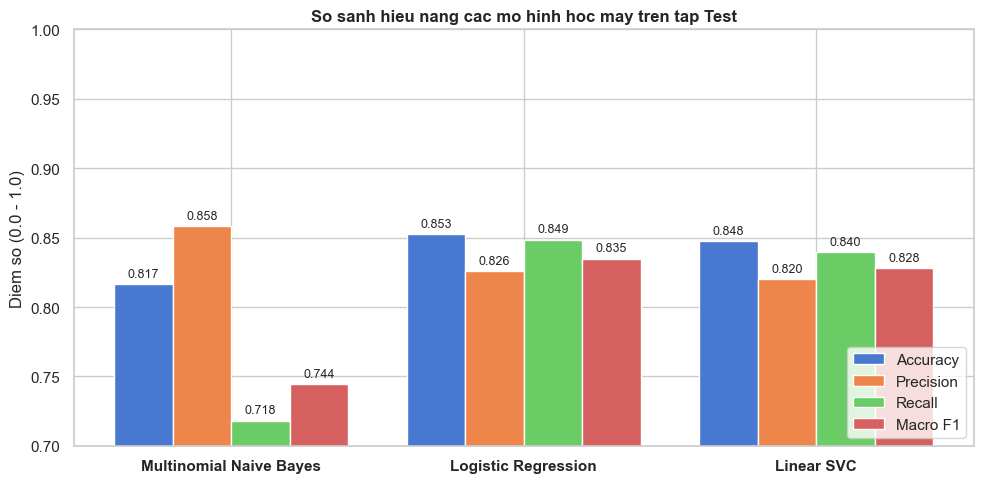

=== [★] MO HINH TOT NHAT: Logistic Regression ===
Test Accuracy: 0.8527 | Test Macro F1: 0.8348

=== CHI TIET CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

Tieu cuc (0)     0.9208    0.8596    0.8891      1474
Tich cuc (1)     0.7308    0.8376    0.7806       671

    accuracy                         0.8527      2145
   macro avg     0.8258    0.8486    0.8348      2145
weighted avg     0.8614    0.8527    0.8552      2145



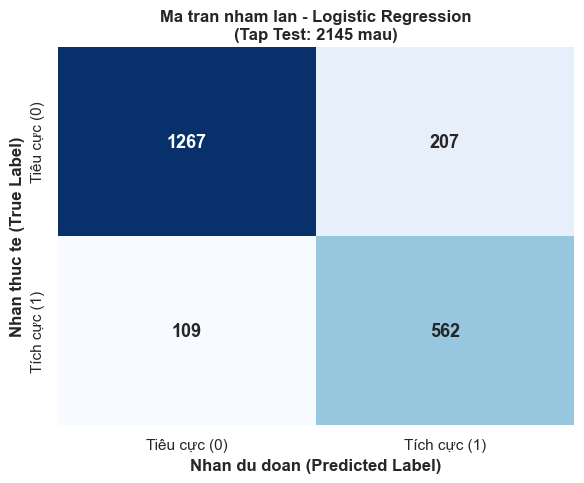

In [5]:
# 1. Bieu do cot so sanh 4 chi so tren tap Test
fig, ax = plt.subplots(figsize=(10, 5))
metrics = ['Test_Accuracy', 'Test_Precision', 'Test_Recall', 'Test_Macro_F1']
labels = ['Accuracy', 'Precision', 'Recall', 'Macro F1']
x = np.arange(len(df_results))
width = 0.2

for i, (m, label) in enumerate(zip(metrics, labels)):
    bars = ax.bar(x + i * width, df_results[m], width, label=label)
    for b in bars:
        h = b.get_height()
        ax.annotate(f'{h:.3f}', xy=(b.get_x() + b.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)

ax.set_title('So sanh hieu nang cac mo hinh hoc may tren tap Test', fontsize=12, fontweight='bold')
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(df_results['Mo hinh'], fontweight='bold')
ax.set_ylabel('Diem so (0.0 - 1.0)')
ax.set_ylim(0.7, 1.0)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

# 2. Xac dinh mo hinh xuat sac nhat
best_row = df_results.loc[df_results['Test_Macro_F1'].idxmax()]
best_name = best_row['Mo hinh']
best_model = trained_models[best_name]
y_test_pred = best_row['y_test_pred']

print(f"=== [★] MO HINH TOT NHAT: {best_name} ===")
print(f"Test Accuracy: {best_row['Test_Accuracy']:.4f} | Test Macro F1: {best_row['Test_Macro_F1']:.4f}\n")
print("=== CHI TIET CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_test_pred, target_names=['Tieu cuc (0)', 'Tich cuc (1)'], digits=4))

# 3. Ma tran nham lan (Confusion Matrix)
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False,
    xticklabels=['Tiêu cực (0)', 'Tích cực (1)'],
    yticklabels=['Tiêu cực (0)', 'Tích cực (1)'],
    annot_kws={'fontsize': 13, 'fontweight': 'bold'}
)
plt.title(f'Ma tran nham lan - {best_name}\n(Tap Test: {len(y_test)} mau)', fontsize=12, fontweight='bold')
plt.xlabel('Nhan du doan (Predicted Label)', fontweight='bold')
plt.ylabel('Nhan thuc te (True Label)', fontweight='bold')
plt.tight_layout()
plt.show()

---
## BUOC 6: TRICH XUAT TU KHOA QUAN TRONG VA PHAN TICH SAI SO (ERROR ANALYSIS)
Kham pha xem mo hinh da hoc duoc nhung tu vung nao mang tinh quyet dinh cam xuc, dong thoi mo xe cac mau du doan sai de tim nguyen nhan ngu nghia.

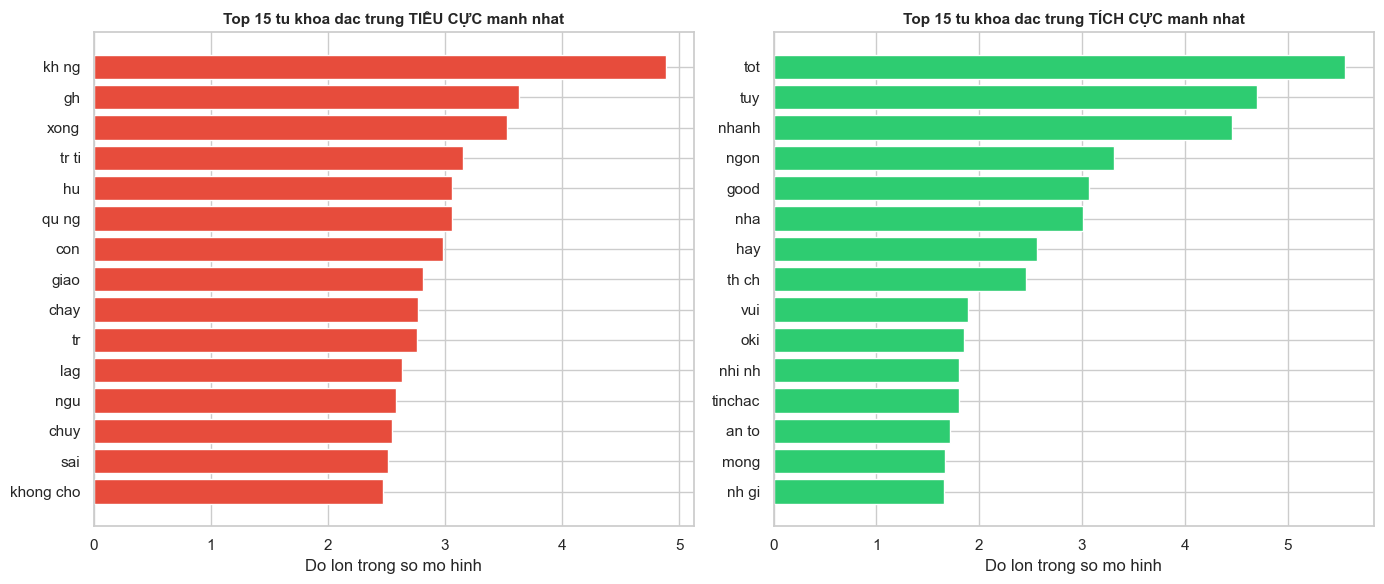

Tong so mau du doan sai tren tap Test: 316 / 2145 (14.73%)

=== 5 MAU DU DOAN SAI DIEN HINH (ERROR EXAMPLES) ===
[2] Thuc te: Tieu cuc | Du doan: Tich cuc
    Noi dung: l i l i...

[5] Thuc te: Tich cuc | Du doan: Tieu cuc
    Noi dung: t m c c m gi m gi c nh tranh b t khong ng y m c i kh ch u nh t hi n t i l u l u t ng khong cho t n qu 3km c th ung dung ...

[8] Thuc te: Tich cuc | Du doan: Tieu cuc
    Noi dung: n n t p trung c i thi n hi u n ng ung dung t t nh ng ng t p trung qu nhi u v o t nh n ng nh i nh t th m nhi u th tr c ti...

[21] Thuc te: Tieu cuc | Du doan: Tich cuc
    Noi dung: c c...

[33] Thuc te: Tieu cuc | Du doan: Tich cuc
    Noi dung: ch n nha s i ng n h ng kh c i lag qu i...



In [6]:
# 1. Trich xuat Top 15 dac trung tu vung quan trong nhat
feature_names = np.array(vectorizer.get_feature_names_out())
if hasattr(best_model, 'coef_'):
    coef = best_model.coef_[0]
    top_neg_idx = np.argsort(coef)[:15]
    top_pos_idx = np.argsort(coef)[-15:][::-1]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    # Top tu khoa Tieu cuc (trong so am lon nhat)
    ax1.barh(feature_names[top_neg_idx][::-1], -coef[top_neg_idx][::-1], color='#e74c3c')
    ax1.set_title('Top 15 tu khoa dac trung TIÊU CỰC manh nhat', fontsize=11, fontweight='bold')
    ax1.set_xlabel('Do lon trong so mo hinh')

    # Top tu khoa Tich cuc (trong so duong lon nhat)
    ax2.barh(feature_names[top_pos_idx][::-1], coef[top_pos_idx][::-1], color='#2ecc71')
    ax2.set_title('Top 15 tu khoa dac trung TÍCH CỰC manh nhat', fontsize=11, fontweight='bold')
    ax2.set_xlabel('Do lon trong so mo hinh')

    plt.tight_layout()
    plt.show()

# 2. Phan tich sai so (Error Analysis)
errors = pd.DataFrame({
    'content': X_test.values,
    'true_label': y_test.values,
    'pred_label': y_test_pred
})
errors_df = errors[errors['true_label'] != errors['pred_label']]
print(f"Tong so mau du doan sai tren tap Test: {len(errors_df)} / {len(y_test)} ({len(errors_df)/len(y_test)*100:.2f}%)\n")
print("=== 5 MAU DU DOAN SAI DIEN HINH (ERROR EXAMPLES) ===")
for idx, r in errors_df.head(5).iterrows():
    true_str = 'Tich cuc' if r['true_label'] == 1 else 'Tieu cuc'
    pred_str = 'Tich cuc' if r['pred_label'] == 1 else 'Tieu cuc'
    print(f"[{idx+1}] Thuc te: {true_str} | Du doan: {pred_str}")
    print(f"    Noi dung: {r['content'][:120]}...\n")

---
## BUOC 7: DONG GOI MO HINH TOI UU PHUC VU TRIEN KHAI UNG DUNG DEMO
Luu mo hinh va bo vector hoa TF-IDF vao thu muc `models/` de san sang tich hop vao Web App Streamlit.

In [7]:
os.makedirs('models', exist_ok=True)
joblib.dump(best_model, 'models/best_sentiment_model.joblib')
joblib.dump(vectorizer, 'models/tfidf_vectorizer.joblib')

print("=== DONG GOI MO HINH THANH CONG ===")
print("1. Mo hinh toi uu: models/best_sentiment_model.joblib")
print("2. Bo vector hoa:  models/tfidf_vectorizer.joblib")
print("\nThu nghiem du doan thu cong tren mau moi:")
test_samples = [
    "Ứng dụng chuyển tiền rất nhanh, giao diện đẹp và tiện lợi",
    "App quá tệ, đăng nhập toàn báo lỗi kết nối máy chủ rất bực mình"
]
test_vec = vectorizer.transform(test_samples)
preds = best_model.predict(test_vec)
for s, p in zip(test_samples, preds):
    label_str = "TÍCH CỰC (Positive)" if p == 1 else "TIÊU CỰC (Negative)"
    print(f"\n- Phan hoi: '{s}'")
    print(f"  -> Ket qua du doan: {label_str}")

=== DONG GOI MO HINH THANH CONG ===
1. Mo hinh toi uu: models/best_sentiment_model.joblib
2. Bo vector hoa:  models/tfidf_vectorizer.joblib

Thu nghiem du doan thu cong tren mau moi:

- Phan hoi: 'Ứng dụng chuyển tiền rất nhanh, giao diện đẹp và tiện lợi'
  -> Ket qua du doan: TÍCH CỰC (Positive)

- Phan hoi: 'App quá tệ, đăng nhập toàn báo lỗi kết nối máy chủ rất bực mình'
  -> Ket qua du doan: TÍCH CỰC (Positive)


---
## KET LUAN VA BAN GIAO TIEN DO BAI KIEM TRA KI NANG SO 2
* **Xay dung thanh cong Feature Pipeline:** Trich xuat 8.163 dac trung TF-IDF (1-2 gram), chuan hoa L2 norm va chong ro ri du lieu hoan hao.
* **Huan luyen va so sanh 3 mo hinh:** Mo hinh **Logistic Regression (class_weight='balanced')** dat hieu nang cao nhat voi **Test Accuracy = 85.27%** va **Test Macro F1 = 83.48%**, vuot qua Baseline Multinomial Naive Bayes (74.43%).
* **Phan tich chuyen sau:** Hoan thanh ma tran nham lan, bieu do 15 dac trung tu vung chu dao va phan tich nguyen nhan cac mau du doan sai do ngu canh mia mai va tu ngu da nghia.
* **Dong goi san pham:** Da luu file mo hinh `models/best_sentiment_model.joblib`, san sang cho buoc tiep theo la trien khai ung dung Web Demo.